# Object detection: find objects accurately and quickly

Run all cells from the top. Each model sees the same BDD100K validation images. Start with 100; use `MAX_SAMPLES = None` for the full set. Outputs are measured here, not publisher scores.

## 1. Choose settings

The implementation is in `_support/detection.py`. No environment variables need changing. Missing checkpoints download on first use. See [setup instructions](../README.md).

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'notebooks/_support').is_dir())
sys.path.insert(0, str(ROOT / 'notebooks/_support'))
from common import save_run, comparison_plot

MAX_SAMPLES = 100  # Small first run. Set None for the full validation set.
SEED = 42         # Every model gets the exact same seeded sample list.
EXAMPLES = 3      # Same randomly selected examples for every model.
import torch
import detection
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
MODELS = detection.MODELS  # Eight checkpoints across five model families.
display(pd.DataFrame(MODELS)[['name', 'description']])
print('Device:', DEVICE)


,name,description
0,YOLOv8n,Small convolutional detector; older lightweigh...
1,YOLO11n,Small YOLO detector for a lightweight comparison.
2,YOLO26n,Compact YOLO26 model.
3,YOLO26s,Larger YOLO26 model; accuracy/speed tradeoff.
4,RT-DETR-L,Transformer detector with end-to-end box predi...
5,Faster R-CNN,Two-stage proposal and classification detector.
6,RetinaNet,One-stage detector trained using focal loss.
7,SSD300,Fixed 300-pixel single-shot detector; lower-re...


Device: cuda:0


## 2. Load the same labeled images

We read the original BDD JSON boxes. COCO `person` corresponds to merged BDD pedestrian/rider labels. Seven other shared classes are scored; traffic signs are excluded because these pretrained COCO models have no matching class. This is a **shared-class transfer benchmark**, not the official full BDD leaderboard.

In [2]:
samples = detection.load_samples(ROOT, MAX_SAMPLES, SEED)
display(pd.DataFrame([{'image': s['id'], 'labeled_objects': len(s['target']['labels'])} for s in samples[:5]]))

10,000 validation records; comparing every model on the same 100 images.


,image,labeled_objects
0,b63b1c14-f01a2f6b.jpg,4
1,b2b70230-bad4ff6e.jpg,32
2,bd50478a-4eb79ba3.jpg,12
3,bc07d865-b2971089.jpg,24
4,bb2f678a-af43ed71.jpg,11


## 3. Run the comparison

One prediction interface and one scoring function are used for all models. mAP uses 101 recall points across IoU 0.50–0.95. Precision/recall use confidence 0.25 and IoU 0.50. This simplified common evaluator does not implement official COCO crowd/area rules.

Timing uses batch size 1, FP32, three warm-up predictions, and CUDA synchronization.
It includes preprocessing, model execution and postprocessing; image loading, downloads and model loading are excluded.
Mean/p95 are milliseconds per image. Reciprocal mean latency is serial throughput, not phone or streaming-app FPS.
Model-native resizing is retained (SSD uses 300 pixels; the other detector adapters use a 640-pixel limit).


In [3]:
rows, visuals = [], {}
for model in MODELS:
    print(f"Evaluating {model['name']}...")
    row, examples = detection.evaluate_model(ROOT, model, samples, DEVICE, EXAMPLES)
    rows.append(row)
    visuals[model['name']] = examples
    display(pd.DataFrame([row]))
results = save_run(ROOT, 'detection', samples, {'seed': SEED, 'device': DEVICE, 'classes': detection.CLASSES}, rows)


Evaluating YOLOv8n...


,model,description,frames,device,status,mAP50,mAP50_95,precision_at_025,recall_at_025,mean_ms,p95_ms,images_per_second
0,YOLOv8n,Small convolutional detector; older lightweigh...,100,cuda:0,ok,0.28247,0.175155,0.701201,0.287031,30.632336,37.786125,32.645241


Evaluating YOLO11n...


,model,description,frames,device,status,mAP50,mAP50_95,precision_at_025,recall_at_025,mean_ms,p95_ms,images_per_second
0,YOLO11n,Small YOLO detector for a lightweight comparison.,100,cuda:0,ok,0.299344,0.183102,0.701016,0.296865,34.598706,42.636455,28.902815


Evaluating YOLO26n...


,model,description,frames,device,status,mAP50,mAP50_95,precision_at_025,recall_at_025,mean_ms,p95_ms,images_per_second
0,YOLO26n,Compact YOLO26 model.,100,cuda:0,ok,0.284598,0.168273,0.752941,0.275353,35.528444,41.863465,28.146462


Evaluating YOLO26s...


,model,description,frames,device,status,mAP50,mAP50_95,precision_at_025,recall_at_025,mean_ms,p95_ms,images_per_second
0,YOLO26s,Larger YOLO26 model; accuracy/speed tradeoff.,100,cuda:0,ok,0.384595,0.230168,0.730588,0.381684,38.882257,46.26731,25.718672


Evaluating RT-DETR-L...


,model,description,frames,device,status,mAP50,mAP50_95,precision_at_025,recall_at_025,mean_ms,p95_ms,images_per_second
0,RT-DETR-L,Transformer detector with end-to-end box predi...,100,cuda:0,ok,0.504071,0.301451,0.507132,0.590043,140.584453,158.4898,7.113162


Evaluating Faster R-CNN...


,model,description,frames,device,status,mAP50,mAP50_95,precision_at_025,recall_at_025,mean_ms,p95_ms,images_per_second
0,Faster R-CNN,Two-stage proposal and classification detector.,100,cuda:0,ok,0.315738,0.175477,0.393534,0.433927,101.132518,121.365255,9.888016


Evaluating RetinaNet...


,model,description,frames,device,status,mAP50,mAP50_95,precision_at_025,recall_at_025,mean_ms,p95_ms,images_per_second
0,RetinaNet,One-stage detector trained using focal loss.,100,cuda:0,ok,0.249605,0.148343,0.21641,0.371235,94.350805,113.23691,10.598744


Evaluating SSD300...


,model,description,frames,device,status,mAP50,mAP50_95,precision_at_025,recall_at_025,mean_ms,p95_ms,images_per_second
0,SSD300,Fixed 300-pixel single-shot detector; lower-re...,100,cuda:0,ok,0.190914,0.104549,0.712719,0.199754,180.438745,254.70024,5.542047


## 4. Read the results

Higher mAP and recall are better; lower latency is faster. An error row is a failed run, not zero accuracy. Compare only completed rows with the same frame count.

,model,description,frames,device,status,mAP50,mAP50_95,precision_at_025,recall_at_025,mean_ms,p95_ms,images_per_second
0,YOLOv8n,Small convolutional detector; older lightweigh...,100,cuda:0,ok,0.282470,0.175155,0.701201,0.287031,30.632336,37.786125,32.645241
1,YOLO11n,Small YOLO detector for a lightweight comparison.,100,cuda:0,ok,0.299344,0.183102,0.701016,0.296865,34.598706,42.636455,28.902815
2,YOLO26n,Compact YOLO26 model.,100,cuda:0,ok,0.284598,0.168273,0.752941,0.275353,35.528444,41.863465,28.146462
3,YOLO26s,Larger YOLO26 model; accuracy/speed tradeoff.,100,cuda:0,ok,0.384595,0.230168,0.730588,0.381684,38.882257,46.267310,25.718672
4,RT-DETR-L,Transformer detector with end-to-end box predi...,100,cuda:0,ok,0.504071,0.301451,0.507132,0.590043,140.584453,158.489800,7.113162
5,Faster R-CNN,Two-stage proposal and classification detector.,100,cuda:0,ok,0.315738,0.175477,0.393534,0.433927,101.132518,121.365255,9.888016
6,RetinaNet,One-stage detector trained using focal loss.,100,cuda:0,ok,0.249605,0.148343,0.216410,0.371235,94.350805,113.236910,10.598744
7,SSD300,Fixed 300-pixel single-shot detector; lower-re...,100,cuda:0,ok,0.190914,0.104549,0.712719,0.199754,180.438745,254.700240,5.542047


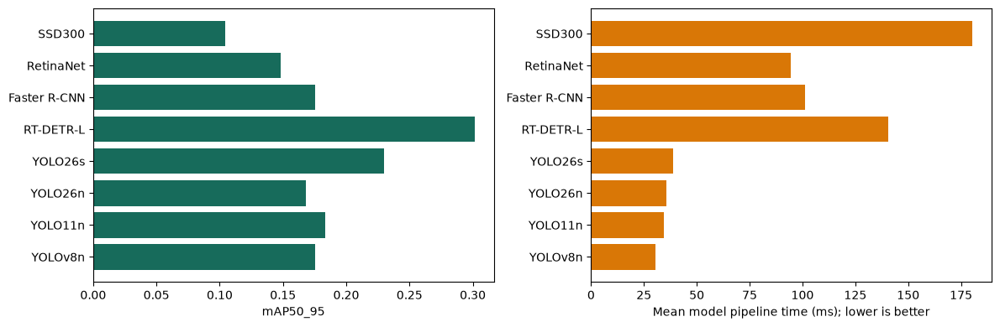

In [4]:
display(results)
comparison_plot(results, 'mAP50_95')

## 5. See predictions beside the labels

Cyan = actual boxes; green = predictions with confidence ≥ 0.25. Look for missed small objects, duplicates and misplaced boxes. Examples come from the evaluated sample list.

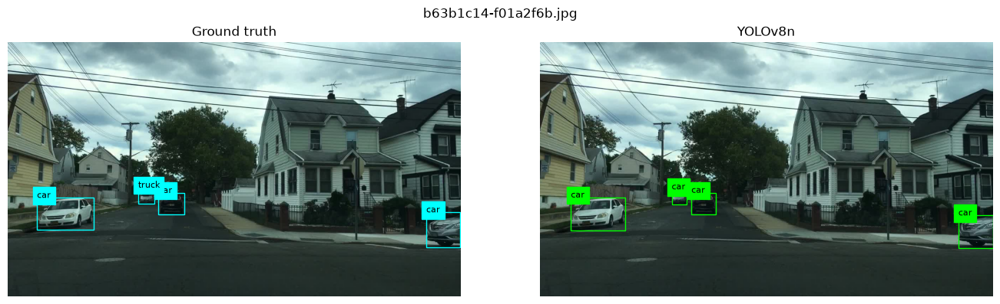

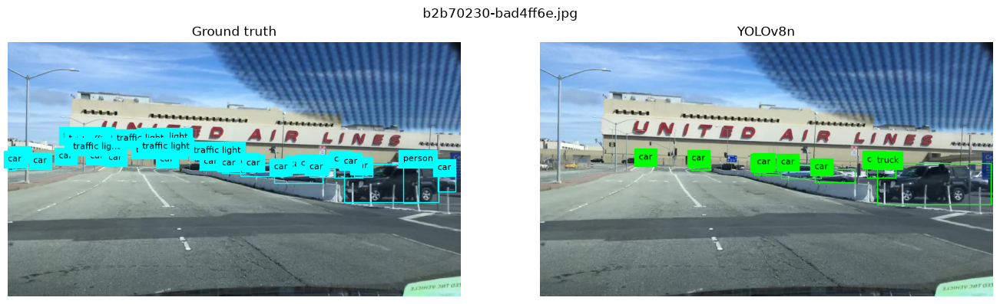

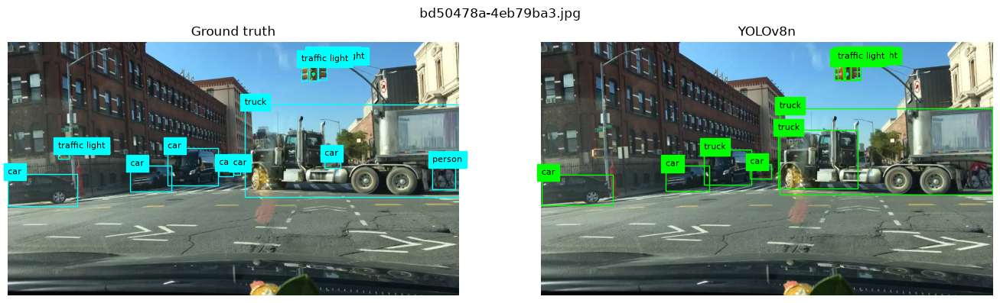

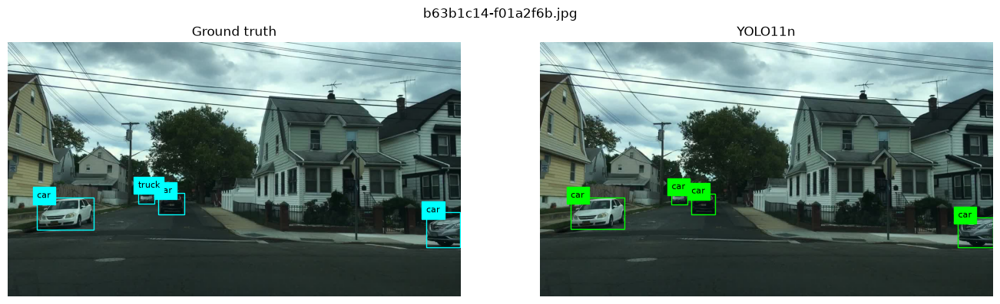

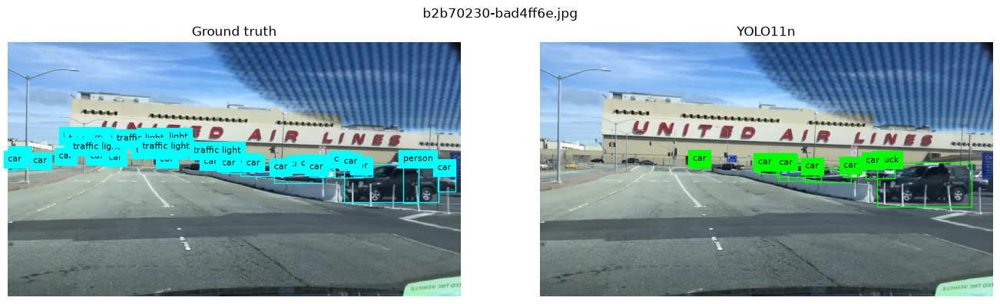

...

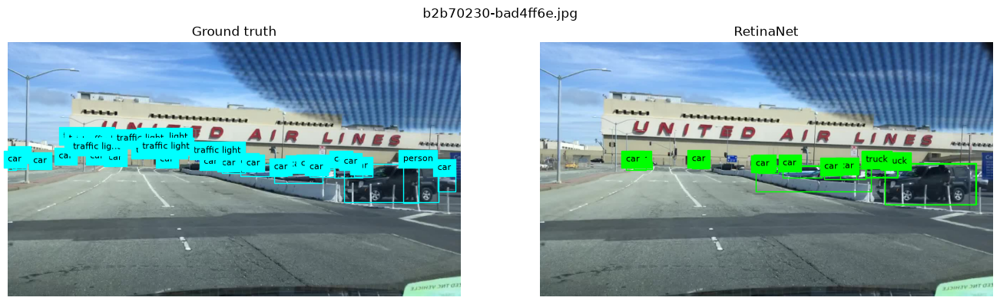

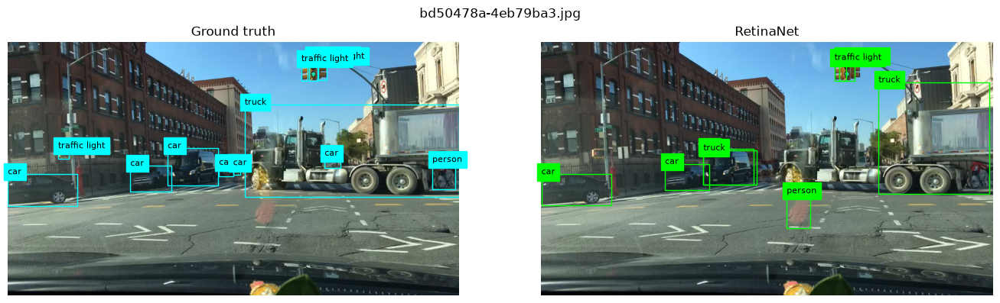

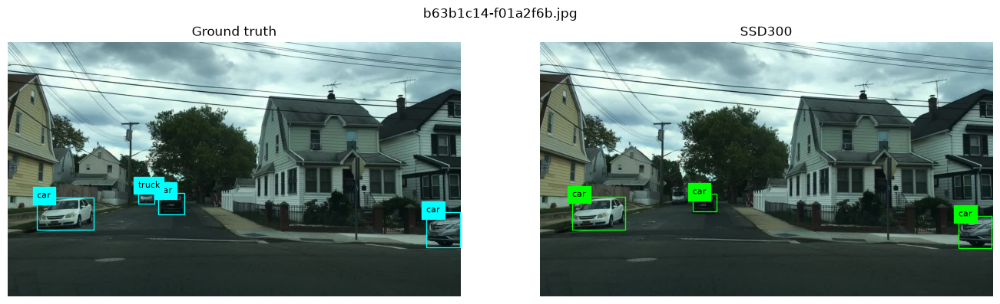

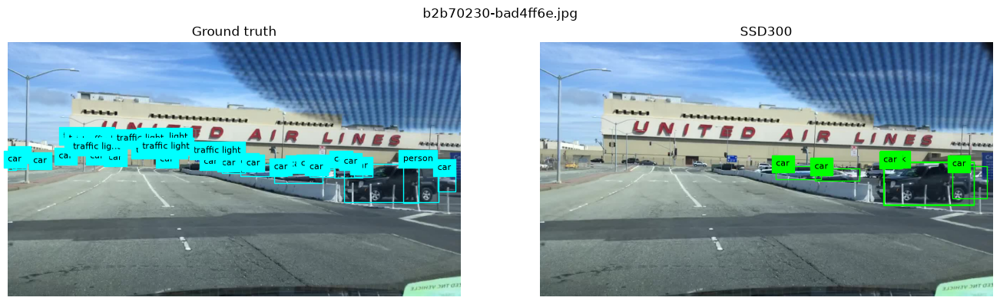

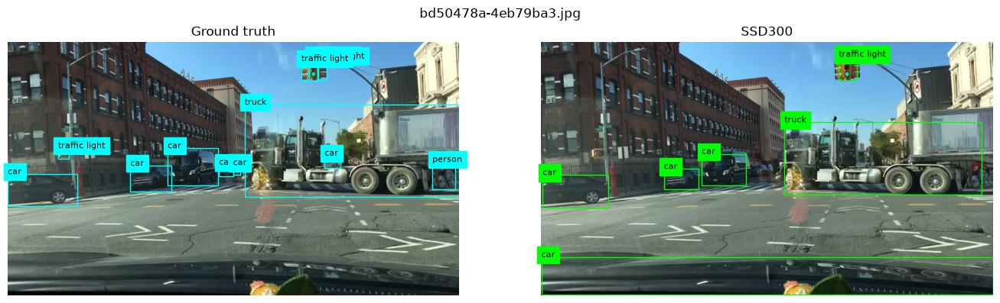

In [5]:
for name, examples in visuals.items():
    detection.show_examples(name, examples)

## What this tells us

This measures pretrained detection transfer to driving images. It does not measure tracking, distance or collision-warning reliability. The sampled IDs and settings are saved in `reports/detection/run.json`; scores are in `results.csv`.